In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
REPO_URL = "github.com/Ayat1807/ElderTrustShield.git"
REPO_DIR = '/content/repo'

if not os.path.exists(REPO_DIR):
    from google.colab import userdata
    token = userdata.get('GITHUB_TOKEN')
    clone_url = f"https://{token}@{REPO_URL}"
    !git clone --recurse-submodules {clone_url} {REPO_DIR}
else:
    !cd {REPO_DIR} && git pull && git submodule update --init --recursive

import sys
sys.path.insert(0, f'{REPO_DIR}/src')
print("Repo ready at", REPO_DIR)

Mounted at /content/drive
Cloning into '/content/repo'...
remote: Enumerating objects: 22, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 22 (delta 1), reused 22 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (22/22), 33.62 KiB | 11.21 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Submodule 'external/DeepfakeBench' (https://github.com/SCLBD/DeepfakeBench.git) registered for path 'external/DeepfakeBench'
Cloning into '/content/repo/external/DeepfakeBench'...
remote: Enumerating objects: 1423, done.        
remote: Total 1423 (delta 0), reused 0 (delta 0), pack-reused 1423 (from 1)        
Receiving objects: 100% (1423/1423), 2.00 MiB | 24.69 MiB/s, done.
Resolving deltas: 100% (929/929), done.
Submodule path 'external/DeepfakeBench': checked out 'f188b1c105465e2e5377eb536a95022ae0e4522d'
Repo ready at /content/repo


In [ ]:
import sys, torch
print("Python version:", sys.version)
print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

# What does DeepfakeBench actually contain?
!find /content/repo/external/DeepfakeBench -maxdepth 2 -type d | sort

Python version: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
Torch version: 2.11.0+cu128
CUDA available: True
/content/repo/external/DeepfakeBench
/content/repo/external/DeepfakeBench/analysis
/content/repo/external/DeepfakeBench/datasets
/content/repo/external/DeepfakeBench/figures
/content/repo/external/DeepfakeBench/preprocessing
/content/repo/external/DeepfakeBench/preprocessing/dataset_json
/content/repo/external/DeepfakeBench/preprocessing/dlib_tools
/content/repo/external/DeepfakeBench/preprocessing/logs
/content/repo/external/DeepfakeBench/training
/content/repo/external/DeepfakeBench/training/config
/content/repo/external/DeepfakeBench/training/dataset
/content/repo/external/DeepfakeBench/training/detectors
/content/repo/external/DeepfakeBench/training/lib
/content/repo/external/DeepfakeBench/training/loss
/content/repo/external/DeepfakeBench/training/metrics
/content/repo/external/DeepfakeBench/training/networks
/content/repo/external/DeepfakeBench/training/optimizor
/c

In [ ]:
# Find UCF-specific code and config
!find /content/repo/external/DeepfakeBench/training/detectors -iname "*ucf*"
!find /content/repo/external/DeepfakeBench/training/config -iname "*ucf*"

# What does the UCF detector actually import? This tells us the REAL
# dependency list for inference, likely much smaller than install.sh's
# full training-pipeline list.
!find /content/repo/external/DeepfakeBench/training/detectors -iname "*ucf*" -exec grep -H "^import\|^from" {} \;

# Does the repo document where to get pretrained (already-trained) weights,
# not just imagenet-pretrained backbones?
!find /content/repo/external/DeepfakeBench -iname "*.md" -path "*pretrain*"
!find /content/repo/external/DeepfakeBench/training/pretrained -maxdepth 2

/content/repo/external/DeepfakeBench/training/detectors/ucf_detector.py
/content/repo/external/DeepfakeBench/training/config/detector/ucf.yaml
/content/repo/external/DeepfakeBench/training/detectors/ucf_detector.py:import os
/content/repo/external/DeepfakeBench/training/detectors/ucf_detector.py:import datetime
/content/repo/external/DeepfakeBench/training/detectors/ucf_detector.py:import logging
/content/repo/external/DeepfakeBench/training/detectors/ucf_detector.py:import random
/content/repo/external/DeepfakeBench/training/detectors/ucf_detector.py:import numpy as np
/content/repo/external/DeepfakeBench/training/detectors/ucf_detector.py:from sklearn import metrics
/content/repo/external/DeepfakeBench/training/detectors/ucf_detector.py:from typing import Union
/content/repo/external/DeepfakeBench/training/detectors/ucf_detector.py:from collections import defaultdict
/content/repo/external/DeepfakeBench/training/detectors/ucf_detector.py:import torch
/content/repo/external/DeepfakeBe

In [ ]:
print("=== pretrained/readme.md ===")
!cat /content/repo/external/DeepfakeBench/training/pretrained/readme.md

print("\n=== ucf.yaml config ===")
!cat /content/repo/external/DeepfakeBench/training/config/detector/ucf.yaml

print("\n=== networks/__init__.py (what BACKBONE actually is) ===")
!cat /content/repo/external/DeepfakeBench/training/networks/__init__.py

=== pretrained/readme.md ===
Put the pretrained weights here.
=== ucf.yaml config ===
# log dir 
log_dir: /data/home/zhiyuanyan/DeepfakeBench/debug_logs/ucf

# model setting
pretrained: ./training/pretrained/xception-b5690688.pth   # path to a pre-trained model, if using one
# pretrained: '/home/zhiyuanyan/.cache/torch/hub/checkpoints/resnet34-b627a593.pth'   # path to a pre-trained model, if using one
model_name: ucf   # model name
backbone_name: xception  # backbone name
encoder_feat_dim: 512  # feature dimension of the backbone

#backbone setting
backbone_config:
  mode: adjust_channel
  num_classes: 2
  inc: 3
  dropout: false

# dataset
all_dataset: [FaceForensics++, FF-F2F, FF-DF, FF-FS, FF-NT, FaceShifter, DeepFakeDetection, Celeb-DF-v1, Celeb-DF-v2, DFDCP, DFDC, DeeperForensics-1.0, UADFV]
train_dataset: [FF-F2F, FF-DF, FF-FS, FF-NT,]
test_dataset: [Celeb-DF-v2]
dataset_type: pair

compression: c23  # compression-level for videos
train_batchSize: 16   # training batch size
test

In [ ]:
import requests

resp = requests.get("https://api.github.com/repos/SCLBD/DeepfakeBench/releases/tags/v1.0.1")
assets = resp.json().get("assets", [])
for a in assets:
    print(a["name"], "-", round(a["size"] / 1e6, 1), "MB")

capsule_best.pth - 15.7 MB
cnnaug_best.pth - 85.3 MB
core_best.pth - 87.8 MB
effnb4_best.pth - 71.0 MB
f3net_best.pth - 90.4 MB
ffd_best.pth - 87.8 MB
meso4Incep_best.pth - 0.1 MB
meso4_best.pth - 0.1 MB
recce_best.pth - 191.5 MB
spsl_best.pth - 87.8 MB
srm_best.pth - 222.1 MB
ucf_best.pth - 188.0 MB
xception_best.pth - 87.8 MB


In [ ]:
import os
os.makedirs('/content/repo/external/DeepfakeBench/training/weights', exist_ok=True)

!wget -q --show-progress -O /content/repo/external/DeepfakeBench/training/weights/ucf_best.pth \
  https://github.com/SCLBD/DeepfakeBench/releases/download/v1.0.1/ucf_best.pth

import os
size_mb = os.path.getsize('/content/repo/external/DeepfakeBench/training/weights/ucf_best.pth') / 1e6
print(f"Downloaded: {size_mb:.1f} MB (expected ~188.0 MB)")

# Look at test.py's actual model-loading logic before writing our own inference call
!sed -n '1,80p' /content/repo/external/DeepfakeBench/training/test.py

/content/repo/exter 100%[===================>] 179.30M  76.9MB/s    in 2.3s    
Downloaded: 188.0 MB (expected ~188.0 MB)
"""
eval pretained model.
"""
import os
import numpy as np
from os.path import join
import cv2
import random
import datetime
import time
import yaml
import pickle
from tqdm import tqdm
from copy import deepcopy
from PIL import Image as pil_image
from metrics.utils import get_test_metrics
import torch
import torch.nn as nn
import torch.nn.parallel
import torch.backends.cudnn as cudnn
import torch.nn.functional as F
import torch.utils.data
import torch.optim as optim

from dataset.abstract_dataset import DeepfakeAbstractBaseDataset
from dataset.ff_blend import FFBlendDataset
from dataset.fwa_blend import FWABlendDataset
from dataset.pair_dataset import pairDataset

from trainer.trainer import Trainer
from detectors import DETECTOR
from metrics.base_metrics_class import Recorder
from collections import defaultdict

import argparse
from logger import create_logger

pars

In [ ]:
!sed -n '80,180p' /content/repo/external/DeepfakeBench/training/test.py

    for one_test_name in config['test_dataset']:
        test_data_loaders[one_test_name] = get_test_data_loader(config, one_test_name)
    return test_data_loaders


def choose_metric(config):
    metric_scoring = config['metric_scoring']
    if metric_scoring not in ['eer', 'auc', 'acc', 'ap']:
        raise NotImplementedError('metric {} is not implemented'.format(metric_scoring))
    return metric_scoring


def test_one_dataset(model, data_loader):
    prediction_lists = []
    feature_lists = []
    label_lists = []
    for i, data_dict in tqdm(enumerate(data_loader), total=len(data_loader)):
        # get data
        data, label, mask, landmark = \
        data_dict['image'], data_dict['label'], data_dict['mask'], data_dict['landmark']
        label = torch.where(data_dict['label'] != 0, 1, 0)
        # move data to GPU
        data_dict['image'], data_dict['label'] = data.to(device), label.to(device)
        if mask is not None:
            data_dict['mask'] = mask.to(device)
 

In [ ]:
!sed -n '175,230p' /content/repo/external/DeepfakeBench/training/test.py

    # prepare the model (detector)
    model_class = DETECTOR[config['model_name']]
    model = model_class(config).to(device)
    epoch = 0
    if weights_path:
        try:
            epoch = int(weights_path.split('/')[-1].split('.')[0].split('_')[2])
        except:
            epoch = 0
        ckpt = torch.load(weights_path, map_location=device)
        model.load_state_dict(ckpt, strict=True)
        print('===> Load checkpoint done!')
    else:
        print('Fail to load the pre-trained weights')
    
    # start testing
    best_metric = test_epoch(model, test_data_loaders)
    print('===> Test Done!')

if __name__ == '__main__':
    main()


In [ ]:
%cd /content/repo/external/DeepfakeBench
import sys
sys.path.insert(0, 'training')

import yaml, torch
from detectors import DETECTOR

with open('training/config/detector/ucf.yaml', 'r') as f:
    config = yaml.safe_load(f)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("DEVICE=", device)

model_class = DETECTOR[config['model_name']]
model = model_class(config).to(device)
print("MODEL_CLASS=", model_class.__name__)

ckpt = torch.load('training/weights/ucf_best.pth', map_location=device)
model.load_state_dict(ckpt, strict=True)
model.eval()
print("CHECKPOINT_LOADED= True")

# Smoke test: random noise, just confirming the forward pass runs end to end
dummy_image = torch.randn(1, 3, 256, 256).to(device)
dummy_label = torch.zeros(1, dtype=torch.long).to(device)
data_dict = {'image': dummy_image, 'label': dummy_label, 'mask': None, 'landmark': None}

with torch.no_grad():
    predictions = model(data_dict, inference=True)

print("OUTPUT_KEYS=", predictions.keys())
print("PROB=", predictions['prob'])

/content/repo/external/DeepfakeBench


ImportError: cannot import name 'setup_environment' from partially initialized module 'slowfast.utils.env' (most likely due to a circular import) (/content/repo/external/DeepfakeBench/training/detectors/utils/slowfast/utils/env.py)

In [ ]:
!cat /content/repo/external/DeepfakeBench/training/detectors/__init__.py

import os
import sys
current_file_path = os.path.abspath(__file__)
parent_dir = os.path.dirname(os.path.dirname(current_file_path))
project_root_dir = os.path.dirname(parent_dir)
sys.path.append(parent_dir)
sys.path.append(project_root_dir)

from metrics.registry import DETECTOR
from .utils import slowfast

from .facexray_detector import FaceXrayDetector
from .xception_detector import XceptionDetector
from .efficientnetb4_detector import EfficientDetector
from .resnet34_detector import ResnetDetector
from .f3net_detector import F3netDetector
from .meso4_detector import Meso4Detector
from .meso4Inception_detector import Meso4InceptionDetector
from .spsl_detector import SpslDetector
from .core_detector import CoreDetector
from .capsule_net_detector import CapsuleNetDetector
from .srm_detector import SRMDetector
from .ucf_detector import UCFDetector
from .recce_detector import RecceDetector
from .fwa_detector import FWADetector
from .ffd_detector import FFDDetector
from .videomae_detector

In [ ]:
!pip install -q fvcore iopath

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 4.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 8.9 MB/s eta 0:00:00


In [ ]:
init_path = 'external/DeepfakeBench/training/detectors/__init__.py'  # relative to /content/repo
full_path = f'/content/repo/{init_path}'

lines_to_disable = [
    "from .utils import slowfast",
    "from .videomae_detector import VideoMAEDetector",
    "from .clip_detector import CLIPDetector",
    "from .timesformer_detector import TimeSformerDetector",
    "from .xclip_detector import XCLIPDetector",
    "from .ftcn_detector import FTCNDetector",
    "from .i3d_detector import I3DDetector",
    "from .altfreezing_detector import AltFreezingDetector",
    "from .stil_detector import STILDetector",
    "from .tall_detector import TALLDetector",
    "from .effort_detector import EffortDetector",
]

with open(full_path, 'r') as f:
    content = f.read()

for line in lines_to_disable:
    content = content.replace(line, f"# {line}  # disabled: video/CLIP detector, not needed for UCF")

with open(full_path, 'w') as f:
    f.write(content)

print("Patched. Disabled lines:")
!grep "# disabled" {full_path}

Patched. Disabled lines:
# from .utils import slowfast  # disabled: video/CLIP detector, not needed for UCF
# from .videomae_detector import VideoMAEDetector  # disabled: video/CLIP detector, not needed for UCF
# from .clip_detector import CLIPDetector  # disabled: video/CLIP detector, not needed for UCF
# from .timesformer_detector import TimeSformerDetector  # disabled: video/CLIP detector, not needed for UCF
# from .xclip_detector import XCLIPDetector  # disabled: video/CLIP detector, not needed for UCF
# from .ftcn_detector import FTCNDetector  # disabled: video/CLIP detector, not needed for UCF
# from .i3d_detector import I3DDetector  # disabled: video/CLIP detector, not needed for UCF
# from .altfreezing_detector import AltFreezingDetector  # disabled: video/CLIP detector, not needed for UCF
# from .stil_detector import STILDetector  # disabled: video/CLIP detector, not needed for UCF
# from .tall_detector import TALLDetector  # disabled: video/CLIP detector, not needed for UCF
#

In [ ]:
%cd /content/repo/external/DeepfakeBench
import sys
sys.path.insert(0, 'training')

import yaml, torch
from detectors import DETECTOR

with open('training/config/detector/ucf.yaml', 'r') as f:
    config = yaml.safe_load(f)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("DEVICE=", device)

model_class = DETECTOR[config['model_name']]
model = model_class(config).to(device)
print("MODEL_CLASS=", model_class.__name__)

ckpt = torch.load('training/weights/ucf_best.pth', map_location=device)
model.load_state_dict(ckpt, strict=True)
model.eval()
print("CHECKPOINT_LOADED= True")

dummy_image = torch.randn(1, 3, 256, 256).to(device)
dummy_label = torch.zeros(1, dtype=torch.long).to(device)
data_dict = {'image': dummy_image, 'label': dummy_label, 'mask': None, 'landmark': None}

with torch.no_grad():
    predictions = model(data_dict, inference=True)

print("OUTPUT_KEYS=", predictions.keys())
print("PROB=", predictions['prob'])

/content/repo/external/DeepfakeBench


AttributeError: `np.sctypes` was removed in the NumPy 2.0 release. Access dtypes explicitly instead.

In [ ]:
!pip install -q efficientnet_pytorch

  Preparing metadata (setup.py) ... done


In [ ]:
!pip install -q kornia

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 91.5 MB/s eta 0:00:00


In [ ]:
!pip install -q imgaug

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 948.0/948.0 kB 23.2 MB/s eta 0:00:00


In [ ]:
import subprocess
result = subprocess.run(
    ['python', '-c', 'import sys; sys.path.insert(0, "training"); from detectors import DETECTOR'],
    capture_output=True, text=True, cwd='/content/repo/external/DeepfakeBench'
)
print(result.stderr)

Traceback (most recent call last):
  File "<string>", line 1, in <module>
    import sys; sys.path.insert(0, "training"); from detectors import DETECTOR
                                                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/repo/external/DeepfakeBench/training/detectors/__init__.py", line 37, in <module>
    from .sladd_detector import SLADDXceptionDetector
  File "/content/repo/external/DeepfakeBench/training/detectors/sladd_detector.py", line 46, in <module>
    from dataset.pair_dataset import pairDataset
  File "/content/repo/external/DeepfakeBench/training/dataset/__init__.py", line 10, in <module>
    from .I2G_dataset import I2GDataset
  File "/content/repo/external/DeepfakeBench/training/dataset/I2G_dataset.py", line 20, in <module>
    from dataset.utils.bi_online_generation import random_get_hull
  File "/content/repo/external/DeepfakeBench/training/dataset/utils/bi_online_generation.py", line 10, in <module>
    from imgaug import augmenters as iaa
 

In [ ]:
import numpy as np

np.sctypes = {
    'int': [np.int8, np.int16, np.int32, np.int64],
    'uint': [np.uint8, np.uint16, np.uint32, np.uint64],
    'float': [np.float16, np.float32, np.float64, np.longdouble],
    'complex': [np.complex64, np.complex128, np.clongdouble],
    'others': [bool, object, bytes, str, np.void],
}
print("np.sctypes restored:", list(np.sctypes.keys()))

np.sctypes restored: ['int', 'uint', 'float', 'complex', 'others']


In [ ]:
import subprocess
result = subprocess.run(
    ['python', '-c', 'import numpy as np; np.sctypes = {"int":[np.int8,np.int16,np.int32,np.int64],"uint":[np.uint8,np.uint16,np.uint32,np.uint64],"float":[np.float16,np.float32,np.float64,np.longdouble],"complex":[np.complex64,np.complex128,np.clongdouble],"others":[bool,object,bytes,str,np.void]}; import sys; sys.path.insert(0, "training"); from detectors import DETECTOR'],
    capture_output=True, text=True, cwd='/content/repo/external/DeepfakeBench'
)
print(result.stdout)
print(result.stderr[-3000:])

In [ ]:
!pip install -q lmdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 346.8/346.8 kB 11.5 MB/s eta 0:00:00


In [ ]:
import os
os.makedirs('/content/repo/external/DeepfakeBench/preprocessing/dlib_tools', exist_ok=True)

!wget -q --show-progress -O /content/repo/external/DeepfakeBench/preprocessing/dlib_tools/shape_predictor_81_face_landmarks.dat \
  https://github.com/SCLBD/DeepfakeBench/releases/download/v1.0.0/shape_predictor_81_face_landmarks.dat

size_mb = os.path.getsize('/content/repo/external/DeepfakeBench/preprocessing/dlib_tools/shape_predictor_81_face_landmarks.dat') / 1e6
print(f"Downloaded: {size_mb:.1f} MB")

/content/repo/exter 100%[===================>]  18.83M   112MB/s    in 0.2s    
Downloaded: 19.7 MB


In [ ]:
import os
os.makedirs('/content/repo/external/DeepfakeBench/training/pretrained', exist_ok=True)

!wget -q --show-progress -O /tmp/pretrained.zip \
  https://github.com/SCLBD/DeepfakeBench/releases/download/v1.0.0/pretrained.zip
!unzip -o -q /tmp/pretrained.zip -d /content/repo/external/DeepfakeBench/training/pretrained

!ls -la /content/repo/external/DeepfakeBench/training/pretrained/

/tmp/pretrained.zip 100%[===================>] 433.50M   179MB/s    in 2.4s    
total 16
drwxr-xr-x  3 root root 4096 Sep  8 03:18 .
drwxr-xr-x 13 root root 4096 Sep  8 02:48 ..
drwxr-xr-x  2 root root 4096 Sep  8 03:19 pretrained
-rw-r--r--  1 root root   32 Sep  8 02:37 readme.md


In [ ]:
import numpy as np
np.sctypes = {
    'int': [np.int8, np.int16, np.int32, np.int64],
    'uint': [np.uint8, np.uint16, np.uint32, np.uint64],
    'float': [np.float16, np.float32, np.float64, np.longdouble],
    'complex': [np.complex64, np.complex128, np.clongdouble],
    'others': [bool, object, bytes, str, np.void],
}

%cd /content/repo/external/DeepfakeBench
import sys
sys.path.insert(0, 'training')

import yaml, torch
from detectors import DETECTOR

with open('training/config/detector/ucf.yaml', 'r') as f:
    config = yaml.safe_load(f)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("DEVICE=", device)

model_class = DETECTOR[config['model_name']]
model = model_class(config).to(device)
print("MODEL_CLASS=", model_class.__name__)

ckpt = torch.load('training/weights/ucf_best.pth', map_location=device)
model.load_state_dict(ckpt, strict=True)
model.eval()
print("CHECKPOINT_LOADED= True")

dummy_image = torch.randn(1, 3, 256, 256).to(device)
dummy_label = torch.zeros(1, dtype=torch.long).to(device)
data_dict = {'image': dummy_image, 'label': dummy_label, 'mask': None, 'landmark': None}

with torch.no_grad():
    predictions = model(data_dict, inference=True)

print("OUTPUT_KEYS=", predictions.keys())
print("PROB=", predictions['prob'])

/content/repo/external/DeepfakeBench
DEVICE= cuda


FileNotFoundError: [Errno 2] No such file or directory: './training/pretrained/xception-b5690688.pth'

In [ ]:
import os
checks = [
    '/content/repo/external/DeepfakeBench/training/weights/ucf_best.pth',
    '/content/repo/external/DeepfakeBench/preprocessing/dlib_tools/shape_predictor_81_face_landmarks.dat',
    '/content/repo/external/DeepfakeBench/training/pretrained/xception-b5690688.pth',
]
for path in checks:
    exists = os.path.exists(path)
    size = os.path.getsize(path) / 1e6 if exists else 0
    print(f"{'EXISTS' if exists else 'MISSING'} ({size:.1f} MB): {path}")

EXISTS (188.0 MB): /content/repo/external/DeepfakeBench/training/weights/ucf_best.pth
EXISTS (19.7 MB): /content/repo/external/DeepfakeBench/preprocessing/dlib_tools/shape_predictor_81_face_landmarks.dat
MISSING (0.0 MB): /content/repo/external/DeepfakeBench/training/pretrained/xception-b5690688.pth


In [ ]:
import os

# Did the zip file itself download correctly?
if os.path.exists('/tmp/pretrained.zip'):
    print(f"zip exists: {os.path.getsize('/tmp/pretrained.zip') / 1e6:.1f} MB")
else:
    print("zip file missing entirely — download itself failed")

# What's actually inside it, and does the extraction folder have anything at all?
!unzip -l /tmp/pretrained.zip 2>&1 | head -20
print("---")
!find /content/repo/external/DeepfakeBench/training/pretrained -type f

zip exists: 454.6 MB
Archive:  /tmp/pretrained.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
        0  2023-07-06 09:16   pretrained/
 91674713  2023-07-06 09:11   pretrained/xception-b5690688.pth
 87319819  2023-07-06 09:11   pretrained/resnet34-b627a593.pth
310643500  2023-07-06 09:13   pretrained/hrnetv2_w48_imagenet_pretrained.pth
---------                     -------
489638032                     4 files
---
/content/repo/external/DeepfakeBench/training/pretrained/pretrained/xception-b5690688.pth
/content/repo/external/DeepfakeBench/training/pretrained/pretrained/hrnetv2_w48_imagenet_pretrained.pth
/content/repo/external/DeepfakeBench/training/pretrained/pretrained/resnet34-b627a593.pth
/content/repo/external/DeepfakeBench/training/pretrained/readme.md


In [ ]:
import shutil, os

nested = '/content/repo/external/DeepfakeBench/training/pretrained/pretrained'
target = '/content/repo/external/DeepfakeBench/training/pretrained'

for fname in os.listdir(nested):
    shutil.move(os.path.join(nested, fname), os.path.join(target, fname))
os.rmdir(nested)

!ls -la /content/repo/external/DeepfakeBench/training/pretrained/

total 478184
drwxr-xr-x  2 root root      4096 Sep  8 03:21 .
drwxr-xr-x 13 root root      4096 Sep  8 02:48 ..
-rw-r--r--  1 root root 310643500 Jul  6  2023 hrnetv2_w48_imagenet_pretrained.pth
-rw-r--r--  1 root root        32 Sep  8 02:37 readme.md
-rw-------  1 root root  87319819 Jul  6  2023 resnet34-b627a593.pth
-rwxr-xr-x  1 root root  91674713 Jul  6  2023 xception-b5690688.pth


In [ ]:
import numpy as np
np.sctypes = {
    'int': [np.int8, np.int16, np.int32, np.int64],
    'uint': [np.uint8, np.uint16, np.uint32, np.uint64],
    'float': [np.float16, np.float32, np.float64, np.longdouble],
    'complex': [np.complex64, np.complex128, np.clongdouble],
    'others': [bool, object, bytes, str, np.void],
}

%cd /content/repo/external/DeepfakeBench
import sys
sys.path.insert(0, 'training')

import yaml, torch
from detectors import DETECTOR

with open('training/config/detector/ucf.yaml', 'r') as f:
    config = yaml.safe_load(f)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("DEVICE=", device)

model_class = DETECTOR[config['model_name']]
model = model_class(config).to(device)
print("MODEL_CLASS=", model_class.__name__)

ckpt = torch.load('training/weights/ucf_best.pth', map_location=device)
model.load_state_dict(ckpt, strict=True)
model.eval()
print("CHECKPOINT_LOADED= True")

dummy_image = torch.randn(1, 3, 256, 256).to(device)
dummy_label = torch.zeros(1, dtype=torch.long).to(device)
data_dict = {'image': dummy_image, 'label': dummy_label, 'mask': None, 'landmark': None}

with torch.no_grad():
    predictions = model(data_dict, inference=True)

print("OUTPUT_KEYS=", predictions.keys())
print("PROB=", predictions['prob'])

/content/repo/external/DeepfakeBench
DEVICE= cuda
MODEL_CLASS= UCFDetector
CHECKPOINT_LOADED= True
OUTPUT_KEYS= dict_keys(['cls', 'feat'])


KeyError: 'prob'

In [ ]:
print("CLS=", predictions['cls'])
print("CLS_SHAPE=", predictions['cls'].shape)

# cls is likely raw logits, not yet a probability - check with softmax
import torch.nn.functional as F
probs = F.softmax(predictions['cls'], dim=1)
print("PROBS_AFTER_SOFTMAX=", probs)

CLS= tensor([[-0.3411,  0.3227]], device='cuda:0')
CLS_SHAPE= torch.Size([1, 2])
PROBS_AFTER_SOFTMAX= tensor([[0.3399, 0.6601]], device='cuda:0')


In [ ]:
!find /content/repo/external/DeepfakeBench -iname "*.jpg" -o -iname "*.jpeg" -o -iname "*.png" 2>/dev/null | grep -v "node_modules" | head -30

/content/repo/external/DeepfakeBench/training/lib/component/MCT/template5.png
/content/repo/external/DeepfakeBench/training/lib/component/MCT/template2.png
/content/repo/external/DeepfakeBench/training/lib/component/MCT/template8.png
/content/repo/external/DeepfakeBench/training/lib/component/MCT/template7.png
/content/repo/external/DeepfakeBench/training/lib/component/MCT/template1.png
/content/repo/external/DeepfakeBench/training/lib/component/MCT/template4.png
/content/repo/external/DeepfakeBench/training/lib/component/MCT/template0.png
/content/repo/external/DeepfakeBench/training/lib/component/MCT/template9.png
/content/repo/external/DeepfakeBench/training/lib/component/MCT/template6.png
/content/repo/external/DeepfakeBench/training/lib/component/MCT/template3.png
/content/repo/external/DeepfakeBench/training/dataset/library/all_in_one.jpg
/content/repo/external/DeepfakeBench/training/dataset/library/000_0000.png
/content/repo/external/DeepfakeBench/training/dataset/library/001_00

In [ ]:
!find /content/repo/external/DeepfakeBench -iname "*.py" | xargs grep -l "shape_predictor_81\|dlib.get_frontal_face" 2>/dev/null

/content/repo/external/DeepfakeBench/training/dataset/fwa_blend.py
/content/repo/external/DeepfakeBench/training/dataset/utils/face_blend.py
/content/repo/external/DeepfakeBench/preprocessing/preprocess.py


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
REPO_URL = "github.com/Ayat1807/ElderTrustShield.git"
REPO_DIR = '/content/repo'

from google.colab import userdata
token = userdata.get('GITHUB_TOKEN')
clone_url = f"https://{token}@{REPO_URL}"
!git clone --recurse-submodules {clone_url} {REPO_DIR}

# NumPy 2.0 compatibility shim for imgaug (round 6 of the original debugging)
import numpy as np
np.sctypes = {
    'int': [np.int8, np.int16, np.int32, np.int64],
    'uint': [np.uint8, np.uint16, np.uint32, np.uint64],
    'float': [np.float16, np.float32, np.float64, np.longdouble],
    'complex': [np.complex64, np.complex128, np.clongdouble],
    'others': [bool, object, bytes, str, np.void],
}

# Disable video/CLIP detector imports we don't need (round 2)
init_path = f'{REPO_DIR}/external/DeepfakeBench/training/detectors/__init__.py'
lines_to_disable = [
    "from .utils import slowfast",
    "from .videomae_detector import VideoMAEDetector",
    "from .clip_detector import CLIPDetector",
    "from .timesformer_detector import TimeSformerDetector",
    "from .xclip_detector import XCLIPDetector",
    "from .ftcn_detector import FTCNDetector",
    "from .i3d_detector import I3DDetector",
    "from .altfreezing_detector import AltFreezingDetector",
    "from .stil_detector import STILDetector",
    "from .tall_detector import TALLDetector",
    "from .effort_detector import EffortDetector",
]
with open(init_path, 'r') as f:
    content = f.read()
for line in lines_to_disable:
    content = content.replace(line, f"# {line}  # disabled: video/CLIP detector, not needed for UCF")
with open(init_path, 'w') as f:
    f.write(content)

# Missing packages (rounds 1, 3, 4, 5, 7)
!pip install -q fvcore iopath efficientnet_pytorch kornia imgaug lmdb

DFB = f'{REPO_DIR}/external/DeepfakeBench'

# dlib landmark model (round 8)
os.makedirs(f'{DFB}/preprocessing/dlib_tools', exist_ok=True)
!wget -q -O {DFB}/preprocessing/dlib_tools/shape_predictor_81_face_landmarks.dat \
  https://github.com/SCLBD/DeepfakeBench/releases/download/v1.0.0/shape_predictor_81_face_landmarks.dat

# ImageNet backbone weights, fixing the nested-zip layout (rounds 9-10)
os.makedirs(f'{DFB}/training/pretrained', exist_ok=True)
!wget -q -O /tmp/pretrained.zip \
  https://github.com/SCLBD/DeepfakeBench/releases/download/v1.0.0/pretrained.zip
!unzip -o -q /tmp/pretrained.zip -d {DFB}/training/pretrained
import shutil
nested = f'{DFB}/training/pretrained/pretrained'
if os.path.exists(nested):
    for fname in os.listdir(nested):
        shutil.move(os.path.join(nested, fname), os.path.join(f'{DFB}/training/pretrained', fname))
    os.rmdir(nested)

# UCF's real trained checkpoint
os.makedirs(f'{DFB}/training/weights', exist_ok=True)
!wget -q -O {DFB}/training/weights/ucf_best.pth \
  https://github.com/SCLBD/DeepfakeBench/releases/download/v1.0.1/ucf_best.pth

# Verify everything landed correctly before declaring success
checks = {
    'ucf_best.pth': f'{DFB}/training/weights/ucf_best.pth',
    'dlib landmarks': f'{DFB}/preprocessing/dlib_tools/shape_predictor_81_face_landmarks.dat',
    'xception backbone': f'{DFB}/training/pretrained/xception-b5690688.pth',
}
all_ok = True
for name, path in checks.items():
    exists = os.path.exists(path)
    size = os.path.getsize(path) / 1e6 if exists else 0
    print(f"{'OK' if exists else 'MISSING'} ({size:.1f} MB): {name}")
    all_ok = all_ok and exists
print("SETUP_COMPLETE=", all_ok)

Mounted at /content/drive
Cloning into '/content/repo'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 25 (delta 3), reused 25 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 36.94 KiB | 18.47 MiB/s, done.
Resolving deltas: 100% (3/3), done.
Submodule 'external/DeepfakeBench' (https://github.com/SCLBD/DeepfakeBench.git) registered for path 'external/DeepfakeBench'
Cloning into '/content/repo/external/DeepfakeBench'...
remote: Enumerating objects: 1423, done.        
remote: Total 1423 (delta 0), reused 0 (delta 0), pack-reused 1423 (from 1)        
Receiving objects: 100% (1423/1423), 2.00 MiB | 29.70 MiB/s, done.
Resolving deltas: 100% (929/929), done.
Submodule path 'external/DeepfakeBench': checked out 'f188b1c105465e2e5377eb536a95022ae0e4522d'
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 4.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done

In [ ]:
import numpy as np
np.sctypes = {
    'int': [np.int8, np.int16, np.int32, np.int64],
    'uint': [np.uint8, np.uint16, np.uint32, np.uint64],
    'float': [np.float16, np.float32, np.float64, np.longdouble],
    'complex': [np.complex64, np.complex128, np.clongdouble],
    'others': [bool, object, bytes, str, np.void],
}

%cd /content/repo/external/DeepfakeBench
import sys
sys.path.insert(0, 'training')

import yaml, torch
from detectors import DETECTOR

with open('training/config/detector/ucf.yaml', 'r') as f:
    config = yaml.safe_load(f)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("DEVICE=", device)

model_class = DETECTOR[config['model_name']]
model = model_class(config).to(device)
print("MODEL_CLASS=", model_class.__name__)

ckpt = torch.load('training/weights/ucf_best.pth', map_location=device)
model.load_state_dict(ckpt, strict=True)
model.eval()
print("CHECKPOINT_LOADED= True")

dummy_image = torch.randn(1, 3, 256, 256).to(device)
dummy_label = torch.zeros(1, dtype=torch.long).to(device)
data_dict = {'image': dummy_image, 'label': dummy_label, 'mask': None, 'landmark': None}

with torch.no_grad():
    predictions = model(data_dict, inference=True)

print("OUTPUT_KEYS=", predictions.keys())
print("CLS=", predictions['cls'])

import torch.nn.functional as F
probs = F.softmax(predictions['cls'], dim=1)
print("PROBS_AFTER_SOFTMAX=", probs)

/content/repo/external/DeepfakeBench


/content/repo/external/DeepfakeBench/training/detectors/xception_detector.py:21: SyntaxWarning: invalid escape sequence '\s'
  author={Rossler, Andreas and Cozzolino, Davide and Verdoliva, Luisa and Riess, Christian and Thies, Justus and Nie{\ss}ner, Matthias},


DEVICE= cuda
MODEL_CLASS= UCFDetector
CHECKPOINT_LOADED= True
OUTPUT_KEYS= dict_keys(['cls', 'feat'])
CLS= tensor([[-0.3278,  0.3124]], device='cuda:0')
PROBS_AFTER_SOFTMAX= tensor([[0.3452, 0.6548]], device='cuda:0')


In [ ]:
!sed -n '1,60p' /content/repo/external/DeepfakeBench/preprocessing/preprocess.py

# author: Zhiyuan Yan
# email: zhiyuanyan@link.cuhk.edu.cn
# date: 2023-03-29
# description: Data pre-processing script for deepfake dataset.


"""
Original dataset structure before the preprocessing:

-FaceForensics++
    -original_sequences
        -youtube
            -c23
                -videos
                    *.mp4
    -manipulated_sequences
        -Deepfakes
            -c23
                -videos
        -Face2Face
            -c23
                -videos
        -FaceSwap
            -c23
                -videos
        -NeuralTextures
            -c23
                -videos
        -FaceShifter
            -c23
                -videos
        -DeepFakeDetection
            -c23
                -videos
                
-Celeb-DF-v1/v2
    -Celeb-synthesis
        -videos
    -Celeb-real
        -videos
    -YouTube-real
        -videos

-DFDCP
    -method_A
    -method_B
    -original_videos

-DeeperForensics-1.0
    -manipulated_videos
    -source_videos

We then addit

In [ ]:
!find /content/drive -iname "Celeb-DF-v2.zip"

/content/drive/MyDrive/Celeb-DF-v2.zip


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/Celeb-DF-v2.zip"
with zipfile.ZipFile(zip_path, 'r') as zf:
    names = zf.namelist()
    print("TOTAL_ENTRIES=", len(names))
    print("SAMPLE_ENTRIES=")
    for n in names[:10]:
        print(" ", n)
    print("...")
    print("LAST_ENTRIES=")
    for n in names[-5:]:
        print(" ", n)

TOTAL_ENTRIES= 415903
SAMPLE_ENTRIES=
  List_of_testing_videos.txt
  Celeb-real/frames/id0_0000/000.png
  Celeb-real/frames/id0_0000/015.png
  Celeb-real/frames/id0_0000/030.png
  Celeb-real/frames/id0_0000/045.png
  Celeb-real/frames/id0_0000/060.png
  Celeb-real/frames/id0_0000/075.png
  Celeb-real/frames/id0_0000/090.png
  Celeb-real/frames/id0_0000/105.png
  Celeb-real/frames/id0_0000/120.png
...
LAST_ENTRIES=
  YouTube-real/landmarks/00299/402.npy
  YouTube-real/landmarks/00299/417.npy
  YouTube-real/landmarks/00299/432.npy
  YouTube-real/landmarks/00299/447.npy
  YouTube-real/landmarks/00299/462.npy


In [ ]:
import zipfile, os

zip_path = "/content/drive/MyDrive/Celeb-DF-v2.zip"
extract_dir = "/content/celebdf_sample"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zf:
    names = zf.namelist()
    # One real video's frames, one fake video's frames — a handful of frames each
    real_sample = [n for n in names if n.startswith("Celeb-real/frames/id0_0000/")][:5]
    fake_sample = [n for n in names if n.startswith("Celeb-synthesis/frames/") and "/000" in n][:5]
    to_extract = real_sample + fake_sample
    print("Extracting", len(to_extract), "sample files...")
    for name in to_extract:
        zf.extract(name, extract_dir)

print("REAL_SAMPLE=", real_sample)
print("FAKE_SAMPLE=", fake_sample)

Extracting 10 sample files...
REAL_SAMPLE= ['Celeb-real/frames/id0_0000/000.png', 'Celeb-real/frames/id0_0000/015.png', 'Celeb-real/frames/id0_0000/030.png', 'Celeb-real/frames/id0_0000/045.png', 'Celeb-real/frames/id0_0000/060.png']
FAKE_SAMPLE= ['Celeb-synthesis/frames/id0_id16_0000/000.png', 'Celeb-synthesis/frames/id0_id16_0001/000.png', 'Celeb-synthesis/frames/id0_id16_0002/000.png', 'Celeb-synthesis/frames/id0_id16_0003/000.png', 'Celeb-synthesis/frames/id0_id16_0004/000.png']


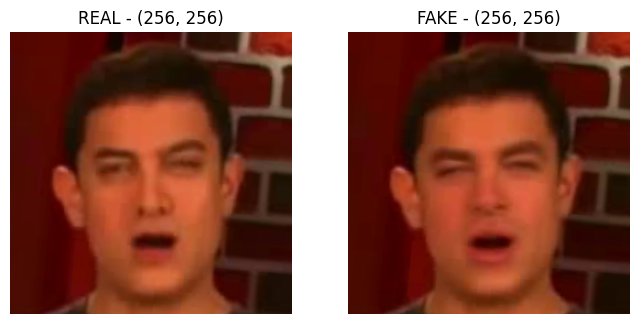

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
real_img = Image.open('/content/celebdf_sample/Celeb-real/frames/id0_0000/000.png')
fake_img = Image.open('/content/celebdf_sample/Celeb-synthesis/frames/id0_id16_0000/000.png')

axes[0].imshow(real_img)
axes[0].set_title(f"REAL - {real_img.size}")
axes[0].axis('off')
axes[1].imshow(fake_img)
axes[1].set_title(f"FAKE - {fake_img.size}")
axes[1].axis('off')
plt.show()

In [ ]:
import numpy as np
import torch

def load_for_ucf(path):
    img = Image.open(path).convert('RGB')
    arr = np.array(img).astype(np.float32) / 255.0
    arr = (arr - 0.5) / 0.5  # matches ucf.yaml: mean=[0.5,0.5,0.5], std=[0.5,0.5,0.5]
    tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)  # HWC -> NCHW
    return tensor.to(device)

real_tensor = load_for_ucf('/content/celebdf_sample/Celeb-real/frames/id0_0000/000.png')
fake_tensor = load_for_ucf('/content/celebdf_sample/Celeb-synthesis/frames/id0_id16_0000/000.png')

import torch.nn.functional as F

with torch.no_grad():
    for name, tensor in [("REAL", real_tensor), ("FAKE", fake_tensor)]:
        dummy_label = torch.zeros(1, dtype=torch.long).to(device)
        data_dict = {'image': tensor, 'label': dummy_label, 'mask': None, 'landmark': None}
        predictions = model(data_dict, inference=True)
        probs = F.softmax(predictions['cls'], dim=1)
        print(f"{name}: probs={probs.cpu().numpy()} (index 0 = predicted-real, index 1 = predicted-fake)")

REAL: probs=[[0.8904592  0.10954088]] (index 0 = predicted-real, index 1 = predicted-fake)
FAKE: probs=[[0.6566624 0.3433376]] (index 0 = predicted-real, index 1 = predicted-fake)


In [ ]:
import zipfile, os

zip_path = "/content/drive/MyDrive/Celeb-DF-v2.zip"
extract_dir = "/content/celebdf_sample2"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zf:
    names = zf.namelist()
    real_videos = sorted(set(n.split('/frames/')[1].split('/')[0] for n in names if n.startswith("Celeb-real/frames/")))
    fake_videos = sorted(set(n.split('/frames/')[1].split('/')[0] for n in names if n.startswith("Celeb-synthesis/frames/")))

    real_pick = real_videos[::len(real_videos)//25][:25]   # 25 spread-out, distinct real videos
    fake_pick = fake_videos[::len(fake_videos)//25][:25]   # 25 spread-out, distinct fake videos

    to_extract = [f"Celeb-real/frames/{v}/000.png" for v in real_pick] + \
                 [f"Celeb-synthesis/frames/{v}/000.png" for v in fake_pick]
    for name in to_extract:
        if name in names:
            zf.extract(name, extract_dir)

print(f"Extracted {len(real_pick)} real videos, {len(fake_pick)} fake videos (1 frame each, distinct videos)")

Extracted 25 real videos, 25 fake videos (1 frame each, distinct videos)


In [ ]:
import numpy as np, torch, torch.nn.functional as F
from PIL import Image

def load_for_ucf(path):
    img = Image.open(path).convert('RGB')
    arr = (np.array(img).astype(np.float32) / 255.0 - 0.5) / 0.5
    return torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(device)

correct_normal = correct_flipped = total = 0
with torch.no_grad():
    for label_name, video_list, folder in [("real", real_pick, "Celeb-real"), ("fake", fake_pick, "Celeb-synthesis")]:
        for v in video_list:
            path = f"{extract_dir}/{folder}/frames/{v}/000.png"
            if not os.path.exists(path):
                continue
            tensor = load_for_ucf(path)
            dummy_label = torch.zeros(1, dtype=torch.long).to(device)
            predictions = model({'image': tensor, 'label': dummy_label, 'mask': None, 'landmark': None}, inference=True)
            probs = F.softmax(predictions['cls'], dim=1).cpu().numpy()[0]
            pred_normal = "real" if probs[0] > probs[1] else "fake"
            pred_flipped = "fake" if probs[0] > probs[1] else "real"
            correct_normal += (pred_normal == label_name)
            correct_flipped += (pred_flipped == label_name)
            total += 1

print(f"Accuracy assuming index0=real: {correct_normal}/{total} = {correct_normal/total:.3f}")
print(f"Accuracy assuming index0=fake (flipped): {correct_flipped}/{total} = {correct_flipped/total:.3f}")

Accuracy assuming index0=real: 31/49 = 0.633
Accuracy assuming index0=fake (flipped): 18/49 = 0.367


In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np, torch, torch.nn.functional as F

fake_scores = []
true_labels = []

with torch.no_grad():
    for label_name, video_list, folder in [("real", real_pick, "Celeb-real"), ("fake", fake_pick, "Celeb-synthesis")]:
        for v in video_list:
            path = f"{extract_dir}/{folder}/frames/{v}/000.png"
            if not os.path.exists(path):
                continue
            tensor = load_for_ucf(path)
            dummy_label = torch.zeros(1, dtype=torch.long).to(device)
            predictions = model({'image': tensor, 'label': dummy_label, 'mask': None, 'landmark': None}, inference=True)
            probs = F.softmax(predictions['cls'], dim=1).cpu().numpy()[0]
            fake_scores.append(probs[1])  # probability of fake
            true_labels.append(1 if label_name == "fake" else 0)

auc = roc_auc_score(true_labels, fake_scores)
print(f"AUC (n={len(true_labels)}): {auc:.4f}")
print(f"For comparison, DeepfakeBench's own published UCF-on-CelebDF-v2 AUC: ~0.75")

AUC (n=49): 0.7633
For comparison, DeepfakeBench's own published UCF-on-CelebDF-v2 AUC: ~0.75
